# Import Libraries for analysis

In [55]:
#import libraries for analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.calibration import LabelEncoder
from  sklearn.model_selection import train_test_split, GridSearchCV,cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC


###**loading dataset**

In [56]:
data = pd.read_csv('C:\\Users\\user\\Downloads\\INX_Future.csv')
data.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


After uploading, the files will be available in the current working directory of your Colab notebook (e.g., `/content/`). You can then load them using pandas as you tried to do before.

In [57]:
#check the data informations
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

there are two data types: Interger and Object

In [58]:
#checking the null calues
data.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

there are no null values in the dataset

In [59]:
#checking the duplicates in the dataset
data.duplicated().sum()

np.int64(0)

there is no duplicates in the datasets

In [60]:
# decribtions of the data
data.describe()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
count,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,2.89250,2.715833,65.981667,2.731667,2.067500,2.732500,2.665000,15.222500,2.725000,11.330000,2.785833,2.744167,7.077500,4.291667,2.194167,4.105000,2.948333
std,9.087289,8.176636,1.04412,1.090599,20.211302,0.707164,1.107836,1.100888,2.469384,3.625918,1.075642,7.797228,1.263446,0.699374,6.236899,3.613744,3.221560,3.541576,0.518866
min,18.000000,1.000000,1.00000,1.000000,30.000000,1.000000,1.000000,1.000000,0.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,30.000000,2.000000,2.00000,2.000000,48.000000,2.000000,1.000000,2.000000,1.000000,12.000000,2.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,3.000000
50%,36.000000,7.000000,3.00000,3.000000,66.000000,3.000000,2.000000,3.000000,2.000000,14.000000,3.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,3.000000
75%,43.000000,14.000000,4.00000,4.000000,83.000000,3.000000,3.000000,4.000000,4.000000,18.000000,4.000000,15.000000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,29.000000,5.00000,4.000000,100.000000,4.000000,5.000000,4.000000,9.000000,25.000000,4.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


there potential outliers in numcomponiesworked,Emplastsalaryhikepercent,TotalWorkExperienceInYears,ExperienceYearsAtThisCompany,YearsWithCurrManager,YearsSinceLastPromotion

In [61]:
#check the shapes
data.shape

(1200, 28)

There are 1200 samples and 28 featuers (variables)

##Create a copy of dataset for analysis

In [62]:
#copy of dataset
data_copy=data.copy()


In [63]:
# Drop most redundant/useless ones
drop_features = [
    'DistanceFromHome',
    'EmpHourlyRate',
    'EmpJobInvolvement',
    'EmpRelationshipSatisfaction',
    'TrainingTimesLastYear',
    'EmpJobSatisfaction',
    'EmpWorkLifeBalance',
    'TotalWorkExperienceInYears',  # Redundant with EmpJobLevel
    'ExperienceYearsInCurrentRole',  # Redundant with ExperienceYearsAtThisCompany
    'YearsWithCurrManager'  # Weak and redundant
]


In [64]:
data_copy.drop(columns=drop_features, inplace=True,axis=1)
data_copy.drop(columns=['EmpNumber'], inplace=True,axis=1)


Drop features which are not important in this case

# Outlier Removal using Inter Quartile Range

In [65]:
#Outlier detection and Removal IQR
def remove_outliers_iqr(data_copy,column):
  Q1=data_copy[column].quantile(0.25)
  Q3=data_copy[column].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR
  outliers=data_copy[(data_copy[column]<lower_bound) | (data_copy[column]>upper_bound)]#Outlier detection
  cleaned=data_copy[(data_copy[column]>=lower_bound) & (data_copy[column]<=upper_bound)] #Outlier Removal
  print(f'Outliers detected in {column}: {len(outliers)}')
  print(f"Before: {data_copy.shape}, After removal: {cleaned.shape}")
  return cleaned

In [66]:
#Remove outliers,YearsSinceLastPromotion,numcomponiesworked,EmpLastSalaryHikePercent,TotalWorkExperienceInYears,ExperienceYearsAtThisCompan y,YearsWithCurrManager,YearsSinceLastPromotion
cleaned_data_iqr=remove_outliers_iqr(data_copy,'YearsSinceLastPromotion')

Outliers detected in YearsSinceLastPromotion: 88
Before: (1200, 17), After removal: (1112, 17)


#**ENCODING**

In [67]:
# Step 1: Define nominal categorical columns for One-Hot Encoding
nominal_cols = ['Gender', 'EducationBackground', 'MaritalStatus',
                'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'Attrition']

# Step 2: Label Encode target columns (PerformanceRating and OverTime) in cleaned_data_iqr
label_cols = ['PerformanceRating', 'OverTime']
le = LabelEncoder()
for col in label_cols:
    cleaned_data_iqr[col] = le.fit_transform(cleaned_data_iqr[col])

# Step 3: One-Hot Encode nominal columns from the now-processed cleaned_data_iqr
# PerformanceRating and OverTime are already numerical and should not be one-hot encoded
data_encoded = pd.get_dummies(cleaned_data_iqr, columns=nominal_cols, drop_first=True)

# Step 4: View the result
data_encoded.head()

,Age,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpJobLevel,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,ExperienceYearsAtThisCompany,YearsSinceLastPromotion,PerformanceRating,...,EmpJobRole_Research Scientist,EmpJobRole_Sales Executive,EmpJobRole_Sales Representative,EmpJobRole_Senior Developer,EmpJobRole_Senior Manager R&D,EmpJobRole_Technical Architect,EmpJobRole_Technical Lead,BusinessTravelFrequency_Travel_Frequently,BusinessTravelFrequency_Travel_Rarely,Attrition_Yes
0,32,3,4,2,1,0,12,10,0,1,...,False,True,False,False,False,False,False,False,True,False
1,47,4,4,2,2,0,12,7,1,1,...,False,True,False,False,False,False,False,False,True,False
2,40,4,4,3,5,1,21,18,1,2,...,False,True,False,False,False,False,False,True,False,False
4,60,4,1,2,8,0,14,2,2,1,...,False,True,False,False,False,False,False,False,True,False
5,27,2,4,3,1,0,21,9,1,2,...,False,False,False,False,False,False,False,True,False,False


#**MODELLLING**

## **Principale component Analysis**

In [68]:
#Identifying the target variable and features
X = data_encoded.drop('PerformanceRating', axis=1)
y = data_encoded['PerformanceRating']

In [69]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [70]:
# Scale features for PCA visualization only (not used in model training)
scaler_viz = StandardScaler()
scaled_data = scaler_viz.fit_transform(X)


In [71]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(scaled_data)
# Visualise high-dimensional data with scatter plot


In [72]:

#Explaining Varinace -How well PC is addressing the data in terms of percentages
#--how much variance each PC explains
print('Explained Vaiance',pca.explained_variance_ratio_)

Explained Vaiance [0.07417384 0.06067333]


Principle component one explains 7.8% and Priciple component two explains 5.7%

In [73]:
#Total Information preserved by the PCs from the original data
print('Total Variance explained',sum(pca.explained_variance_ratio_))

Total Variance explained 0.13484717187322776


total variance is very poor priciple components

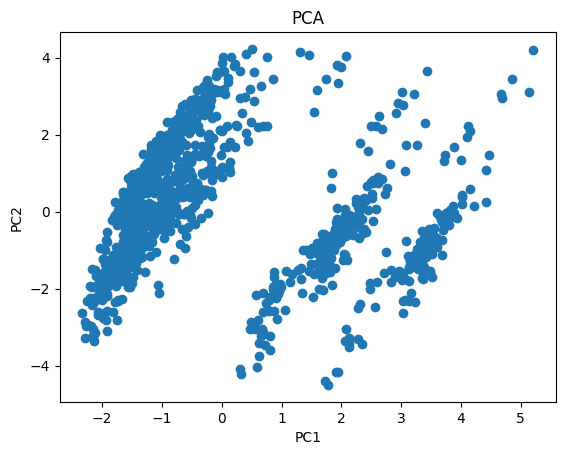

In [74]:
plt.scatter(data_pca[:,0],data_pca[:,1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA')
plt.show()

## This pattern typically suggests that there are three distinct groups or classes in the dataset
## The separation along PC2 is the primary distinguishing feature
##PC1 may represent within-group variability or a secondary characteristic
##therefore this suggests that this is posibly classifications problem that needs to perform logistics regression, random forest classifier etc

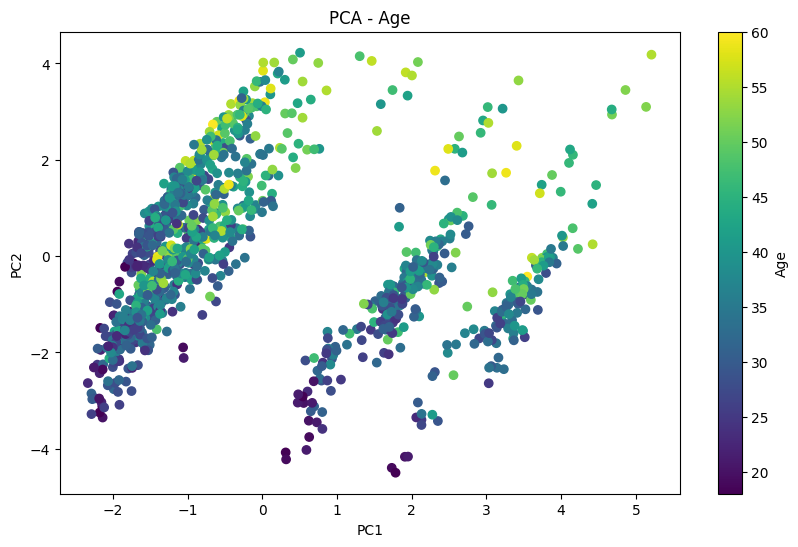

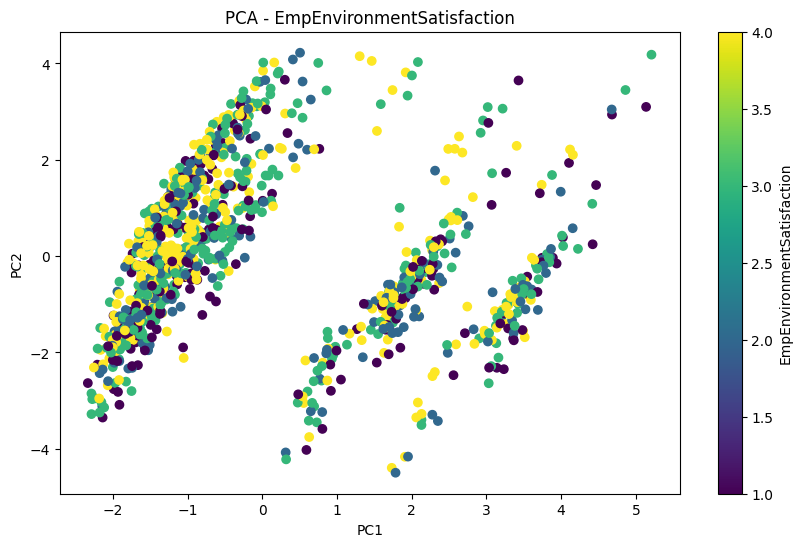

In [75]:
#fo loop section
features=['Age','EmpEnvironmentSatisfaction'] # Corrected typo here
for i, feature in enumerate(features):
  plt.figure(figsize=(10,6))
  plt.scatter(data_pca[:,0],data_pca[:,1],c=data_encoded[feature],cmap='viridis')
  plt.colorbar(label=feature)
  plt.xlabel('PC1')
  plt.ylabel('PC2')
  plt.title(f'PCA - {feature}')
  plt.show()

#**Gradient Boosting Classifier**

In [76]:
#split the dataset into training and testing sets
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [77]:
# Gradient Boosting Classifier - trained directly on original encoded features (no separate scaler/PCA)
model_gb = GradientBoostingClassifier()
model_gb.fit(X_train, y_train)


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [78]:
#make predictions
y_pred_gb=model_gb.predict(X_test)

#classification report
report=classification_report(y_test,y_pred_gb)
print(report)

              precision    recall  f1-score   support

           0       0.85      0.80      0.82        50
           1       0.92      0.98      0.94       246
           2       0.96      0.63      0.76        38

    accuracy                           0.91       334
   macro avg       0.91      0.80      0.84       334
weighted avg       0.91      0.91      0.91       334



## Classification Report Summary

### **Support**
Support illustrates the actual count of samples in each class in the test set:
- **Class 0 (Good):** 50 employees were rated Good
- **Class 1 (Excellent):** 246 employees were rated Excellent  
- **Class 2 (Outstanding):** 38 employees were rated Outstanding

### **Class 0 (Good Performers)**
- **Precision: 0.85** – Out of all employees the model predicted as Good, 85% were correctly predicted
- **Recall: 0.80** – The model found 80% of all employees who were actually rated Good
- **F1-Score: 0.82** – Strong balanced performance for this class



### **Class 1 (Excellent Performers)**
- **Precision: 0.92** – Out of all employees the model predicted as Excellent, 92% were correctly predicted
- **Recall: 0.98** – The model found 98% of all employees who were actually rated Excellent
- **F1-Score: 0.94** – Excellent balanced performance for this class


### **Class 2 (Outstanding Performers)**
- **Precision: 0.96** – Out of all employees the model predicted as Outstanding, 96% were correctly predicted
- **Recall: 0.63** – The model found 63% of all employees who were actually rated Outstanding
- **F1-Score: 0.76** – Good precision but moderate recall, indicating the model is cautious when predicting Outstanding



### **Overall Model Performance**

- **Accuracy: 0.91 (91%)** – The proportion of all predictions that were correct; 91% of all employees were classified correctly

- **Macro Average: 0.91 (Precision), 0.80 (Recall), 0.84 (F1-Score)** – The average performance across all classes, treating each class equally regardless of size

- **Weighted Average: 0.91 (Precision), 0.91 (Recall), 0.91 (F1-Score)** – The average performance weighted by class size; classes with more samples (like Class 1) have more influence on this metric

**Overall:** The model demonstrates** strong performance with 91% accuracy **and shows good balance across all three classes. This represents a high-quality classification model for performance rating prediction.

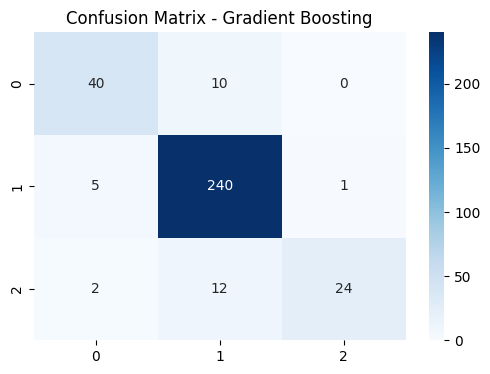

In [79]:
#confusion matrix for Gradient Boosting
cm_gb=confusion_matrix(y_test,y_pred_gb)
plt.figure(figsize=(6,4))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

### **Support**
Support illustrates the actual count of samples in each class in the test set:
- **Class 0 (Good):** 40 model correct identify employees were rated Good
- **Class 1 (Excellent):** 240 model correct identify employees were rated Excellent  
- **Class 2 (Outstanding):** 24 model correct identify employees were rated Outstanding

In [80]:
# Save the model only - no separate scaler or PCA needed
import joblib
joblib.dump(model_gb, 'gradient_boosting_model.pkl')
joblib.dump(scaler_viz, 'scaler_viz.pkl')  # Save the scaler used for PCA visualization
joblib.dump(pca, 'pca.pkl')

print('Model saved successfully.')


Model saved successfully.


In [81]:
# Verify model input features
print('Model was trained on features:', X_train.shape[1])
print('X_test has features:', X_test.shape[1])
print('Feature mismatch:', X_train.shape[1] != X_test.shape[1])
print('No separate scaler or PCA used in model pipeline.')


Model was trained on features: 43
X_test has features: 43
Feature mismatch: False
No separate scaler or PCA used in model pipeline.
